# exp010 — tuning mlp

người thực hiện: như

ngày: 15/11/2026

loại: rerun — đã chạy mới bằng runner chung, không lấy kết quả lịch sử thay lượt này. phần đồ án wesad, tách riêng challenge house prices.

## 1. câu hỏi nghiên cứu

bốn cấu hình lớp ẩn, alpha và learning rate trong lưới g4 có cải thiện macro f1 và balanced accuracy so với mlp mặc định exp006 trên người chưa gặp không? giả thuyết: chọn bằng inner cv có thể tăng hoặc giảm điểm outer test và chưa chắc ổn định giữa các người.

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
from IPython.display import display
candidates = [q for p in [Path.cwd(), *Path.cwd().parents] for q in (p, p / 'wesad-stress-detection')]
root = next(p for p in candidates if (p / 'src/wesad/evaluation.py').is_file())
sys.path.insert(0, str(root / 'scripts'))
import exp010_report as report
run = root / 'outputs/exp010_mlp_nested_20261115_220049_050267'
if not (run / 'verification.json').is_file():
    run = root / 'experiments/02_tuning/EXP-010/results'
print('nguồn kết quả:', run)


nguồn kết quả: C:\Users\LEGION\Desktop\github\Machine-learning\wesad-stress-detection\outputs\exp010_mlp_nested_20261115_220049_050267


## 2. dữ liệu và môi trường

physiological68, 6.189 cửa sổ, 15 người, hai bài toán. kiểm tra schema và checksum trước khi so sánh exp006. binary: stress=1, baseline/amusement=0; multiclass giữ 1/2/3. môi trường chạy ô báo cáo có thể khác môi trường train được lưu trong config.

In [2]:
frame, config, baseline_info = report.data_check(run)
display(pd.crosstab(frame.subject_id, frame.label_original))


ngày chạy: 15/11/2026 | loại: rerun
dữ liệu: 6189 cửa sổ, 15 người, 68 feature
sha256: 2f2fddd678f333a800f2869d2e78b407934b2c3492190ed70e28d8a9107fd8ba
môi trường train exp010: {'python': '3.12.14 | packaged by conda-forge | (main, Sep  2 2026, 23:18:20) [MSC v.1944 64 bit (AMD64)]', 'packages': {'numpy': '2.5.4', 'pandas': '3.1.0', 'PyYAML': '6.0.3', 'scipy': '1.18.1', 'scikit-learn': '1.9.1', 'imbalanced-learn': '0.14.2'}}
baseline exp006: {'python': '3.12.14', 'sklearn': '1.9.1', 'numpy': '2.5.4', 'pandas': '3.1.1'}
không nhận là cùng toàn bộ môi trường: pandas exp006 và exp010 khác phiên bản


label_original    1    2   3
subject_id                  
S10             226  135  65
S11             227  126  64
S13             226  124  67
S14             219  126  65
S15             226  128  64
S16             226  125  64
S17             226  135  65
S2              219  113  63
S3              218  118  65
S4              222  117  65
S5              230  119  65
S6              226  121  65
S7              228  118  65
S8              224  124  64
S9              227  119  65

## 3. protocol

outer loso 15 lượt mỗi bài toán: train 14 người, test 1 người. inner GroupKFold 3 lượt chỉ trên outer train. chọn ứng viên theo macro f1 trung bình của inner validation. imputer median và scaler nằm trong pipeline nên chỉ fit trên train của từng lượt. seed 42; không balancing, feature selection hoặc tối ưu theo outer test. có 30 outer folds, 360 inner fits và 30 refits.

In [3]:
splits = json.loads((run / 'splits.json').read_text(encoding='utf-8'))
example_key = 'multiclass/mlp/S4'
print('ví dụ:', example_key)
print(json.dumps(splits[example_key], ensure_ascii=False, indent=2))
print('số outer folds:', len(splits))


ví dụ: multiclass/mlp/S4
{
  "outer_train_subjects": [
    "S10",
    "S11",
    "S13",
    "S14",
    "S15",
    "S16",
    "S17",
    "S2",
    "S3",
    "S5",
    "S6",
    "S7",
    "S8",
    "S9"
  ],
  "outer_test_subjects": [
    "S4"
  ],
  "inner_splits": [
    {
      "train_subjects": [
        "S10",
        "S13",
        "S15",
        "S16",
        "S2",
        "S3",
        "S5",
        "S7",
        "S8",
        "S9"
      ],
      "validation_subjects": [
        "S11",
        "S14",
        "S17",
        "S6"
      ]
    },
    {
      "train_subjects": [
        "S11",
        "S13",
        "S14",
        "S15",
        "S17",
        "S3",
        "S5",
        "S6",
        "S9"
      ],
      "validation_subjects": [
        "S10",
        "S16",
        "S2",
        "S7",
        "S8"
      ]
    },
    {
      "train_subjects": [
        "S10",
        "S11",
        "S14",
        "S16",
        "S17",
        "S2",
        "S6",
        "S7",
        

## 4. cấu hình

giữ lưới 4 ứng viên đã định trong g4; không chọn lại lưới sau khi xem test. max_iter=200, relu, adam, early_stopping=False. các ứng viên thay đồng thời một số tham số, chưa phải thí nghiệm tách riêng từng yếu tố.

In [4]:
grid = config['settings']['search_spaces']['mlp']
candidate_table = pd.DataFrame([{'candidate': f'c{i+1}', **{k: v[0] for k,v in item.items()}} for i,item in enumerate(grid)])
display(candidate_table)
print('seed:', config['settings']['seed'])
print('điền thiếu median → standard scaler → mlp; max_iter=200')


seed: 42
điền thiếu median → standard scaler → mlp; max_iter=200


  candidate model__hidden_layer_sizes  model__alpha  model__learning_rate_init
0        c1                      [32]        0.0001                      0.001
1        c2                  [64, 32]        0.0010                      0.001
2        c3                      [32]        0.0010                      0.010
3        c4                  [64, 32]        0.0001                      0.010

## 5. code thực thi

runner: scripts/exp010_train.py gọi wesad.evaluation.run_experiment. lượt này đã chạy mới và có checkpoint, inner scores, dự đoán, source snapshot và verification. RUN_TRAIN=False mặc định để đọc kết quả. đổi True sẽ tạo một lượt train mới trong output riêng; không cần đổi chỉ để xem bảng/hình.

In [5]:
import subprocess
RUN_TRAIN = False
train_python = root / '.venv-g1/Scripts/python.exe'
if RUN_TRAIN:
    assert train_python.is_file(), 'chọn đúng python đã cài dependencies của project'
    process = subprocess.Popen([str(train_python), '-u', str(root / 'scripts/exp010_train.py')], cwd=root, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, encoding='utf-8')
    new_run = None
    for line in process.stdout:
        print(line, end='')
        if line.startswith('output: '):
            new_run = Path(line[len('output: '):].strip())
    assert process.wait() == 0, 'runner có lỗi; xem output và checkpoint'
    assert new_run is not None
    run = new_run
    config = json.loads((run / 'config.json').read_text(encoding='utf-8'))
else:
    verification = json.loads((run / 'verification.json').read_text(encoding='utf-8'))
    provenance = json.loads((run / 'notebook_provenance.json').read_text(encoding='utf-8'))
    print('đọc kết quả lượt chạy mới ngày', provenance['date'])
    print('verification:', verification)


đọc kết quả lượt chạy mới ngày 15/11/2026
verification: {'status': 'passed', 'experiment': 'EXP-010', 'outer_folds': 30, 'predictions': 12378, 'candidates_per_outer': 4, 'inner_folds': 3, 'checks': ['checkpoint hashes', 'subject leakage', 'inner winner', 'predictions and labels', 'metrics', 'loss traces', 'sample mean and sd']}


## 6. kết quả và đối chiếu baseline

đối chiếu đúng task, subject, số cửa sổ test và cùng checksum dữ liệu. tính lại điểm baseline từ dự đoán exp006 đã lưu. mean/sd theo 15 người, sd mẫu ddof=1; delta = tuning − baseline.

In [6]:
paired, comparison = report.compare(run)
display(comparison.round(4))
display(paired[["task", "subject_id", "macro_f1_default", "macro_f1_tuned", "delta_macro_f1"]].round(4))


         task             metric  n_subjects  ...  improved  worse  equal
0      binary           macro_f1          15  ...         5      7      3
1      binary  balanced_accuracy          15  ...         5      7      3
2  multiclass           macro_f1          15  ...         5     10      0
3  multiclass  balanced_accuracy          15  ...         7      8      0

[4 rows x 11 columns]

          task subject_id  macro_f1_default  macro_f1_tuned  delta_macro_f1
0   multiclass         S2            0.4257          0.4178         -0.0079
1   multiclass         S3            0.7230          0.7651          0.0421
2   multiclass         S4            0.6212          0.6241          0.0029
3   multiclass         S5            0.7829          0.6950         -0.0879
4   multiclass         S6            0.8735          0.8248         -0.0488
5   multiclass         S7            0.6969          0.5542         -0.1427
6   multiclass         S8            0.6167          0.6103         -0.0065
7   multiclass         S9            0.5297          0.4849         -0.0448
8   multiclass        S10            0.5696          0.5685         -0.0011
9   multiclass        S11            0.7276          0.7314          0.0037
10  multiclass        S13            0.5700          0.6034          0.0334
11  multiclass        S14            0.6257          0.5063         -0.1194
12  multicla

## 7. tham số, hội tụ và hình

loss được ghi khi ứng viên thắng refit trên 14 người outer train. không gọi đó là loss test hoặc validation. warning được runner gom cho toàn bộ inner search/refit nên chưa tách cảnh báo riêng từng ứng viên.

          task subject_id  ...  warning_count warnings
0   multiclass         S2  ...              0         
1   multiclass         S3  ...              0         
2   multiclass         S4  ...              0         
3   multiclass         S5  ...              0         
4   multiclass         S6  ...              0         
5   multiclass         S7  ...              0         
6   multiclass         S8  ...              0         
7   multiclass         S9  ...              0         
8   multiclass        S10  ...              0         
9   multiclass        S11  ...              0         
10  multiclass        S13  ...              0         
11  multiclass        S14  ...              0         
12  multiclass        S15  ...              0         
13  multiclass        S16  ...              0         
14  multiclass        S17  ...              0         
15      binary         S2  ...              0         
16      binary         S3  ...              0         
17      bi

<Figure size 1200x700 with 2 Axes>

<Figure size 1200x400 with 2 Axes>

<Figure size 1000x400 with 2 Axes>

<Figure size 800x400 with 1 Axes>

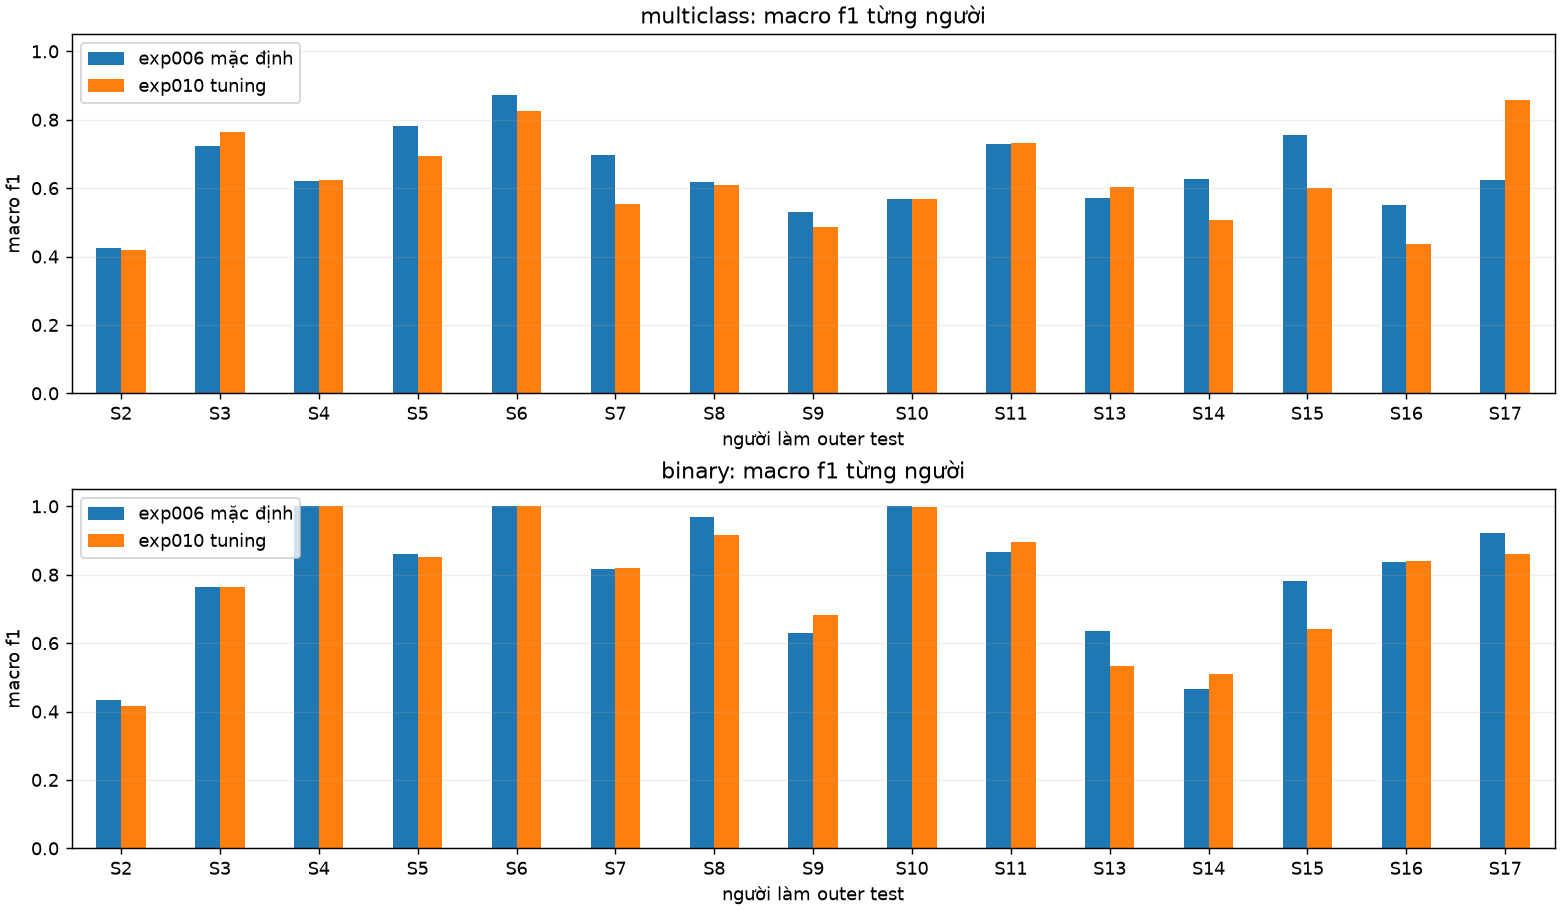

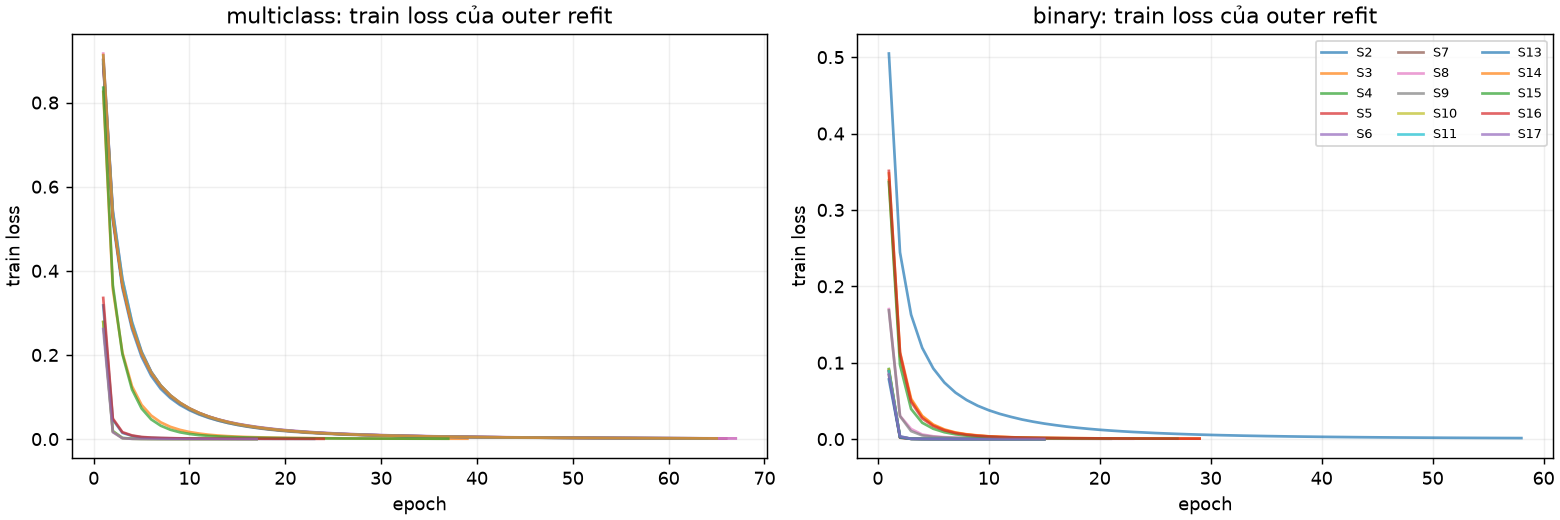

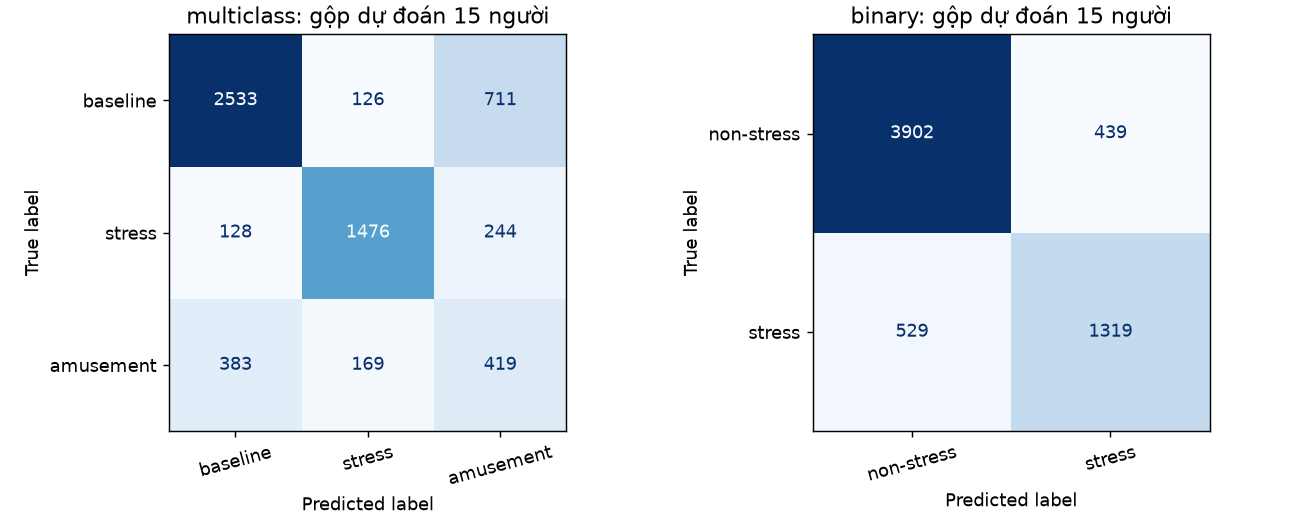

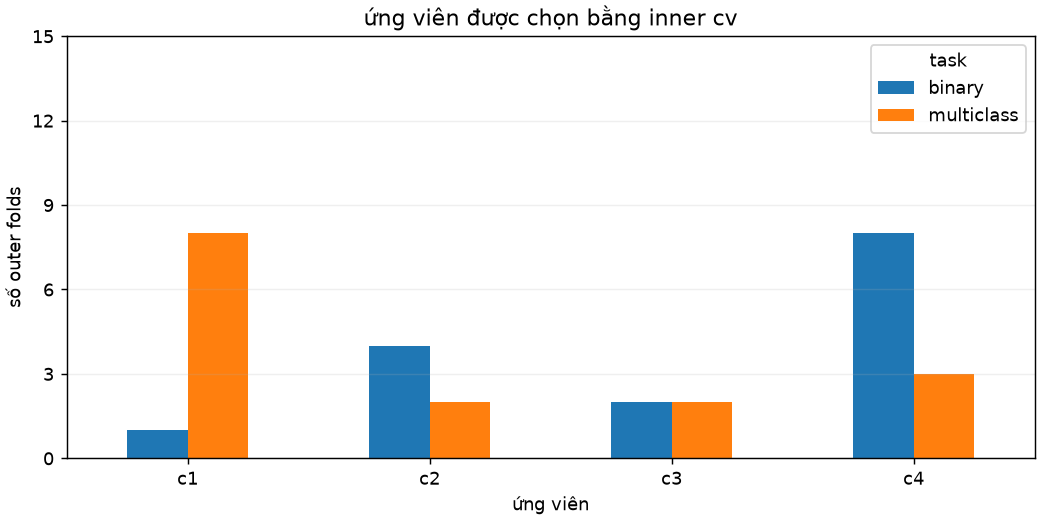

In [7]:
if (run / 'folds').is_dir():
    convergence, losses = report.details(run)
else:
    convergence = pd.read_csv(run / 'convergence.csv')
    losses = json.loads((run / 'loss_traces.json').read_text(encoding='utf-8'))
display(convergence)
report.figures(run, paired, convergence, losses)


## 8. phân tích và kết luận

giữ cả kết quả giảm so với baseline. không thay đổi tham số để làm đẹp điểm outer test. đây là so sánh mô tả, chưa có kiểm định ý nghĩa thống kê.

In [8]:
conclusion = report.conclusion(run, comparison, convergence)


## nhận xét kết quả — 15/11/2026

- binary: macro f1 tuning 0.7819 ± 0.1869; baseline 0.7986 ± 0.1846; giảm 0.0167. 5 người tăng, 7 người giảm, 3 người bằng nhau.
- multiclass: macro f1 tuning 0.6187 ± 0.1338; baseline 0.6462 ± 0.1144; giảm 0.0275. 5 người tăng, 10 người giảm, 0 người bằng nhau.

có 0/30 outer folds ghi cảnh báo trong quá trình search/refit. 0/30 mô hình refit chạm max_iter=200.
số epoch refit từ 15 đến 67.

train loss thuộc mô hình tốt nhất refit trên outer train, không phải validation loss. cảnh báo được runner gom cho cả search và refit, chưa gán riêng từng ứng viên.

tuning không đảm bảo cải thiện trên người mới. kết luận chỉ áp dụng cho bốn cấu hình đã khai báo; các cấu hình thay nhiều tham số cùng lúc nên chưa tách được ảnh hưởng riêng của alpha hay kiến trúc.

so sánh dùng cùng dữ liệu và subject, sklearn 1.9.1. baseline dùng pandas 3.1.1, lượt tuning dùng pandas 3.1.0; chưa kiểm tra độ nhạy với khác biệt này. đây là so sánh mô tả, chưa kiểm định ý nghĩa thống k

## 9. provenance và nhật ký

code train và source snapshot lưu cùng kết quả. cấu hình, môi trường train, hash dữ liệu, splits, inner scores và dự đoán đều có trong gói exp010. git metadata có thể null nếu runner không đọc được repo; không tự gán commit cho mã chưa commit.

phần còn có thể nâng cấp: gán warning theo từng ứng viên; vẽ learning curve theo số người train; kiểm tra độ nhạy giữa các môi trường; kiểm định ghép cặp theo người. không làm các hướng cân bằng lớp exp015 hay kiến trúc mới exp020 trong notebook này.

In [9]:
print('source git commit:', config.get('git_commit'))
print('source code sha256:', config['code_sha256'])
print('data sha256:', config['data_sha256'])
print('nguồn baseline:', report.BASE)
print('nguồn tuning:', run)
print('ngày thực hiện:', json.loads((run / 'notebook_provenance.json').read_text(encoding='utf-8'))['date'])


source git commit: None
source code sha256: fb81c842456e0a9ca7cec935c0f6c5628dc723bf20c70f84465e0279b6a1d057
data sha256: 2f2fddd678f333a800f2869d2e78b407934b2c3492190ed70e28d8a9107fd8ba
nguồn baseline: C:\Users\LEGION\Desktop\github\Machine-learning\wesad-stress-detection\experiments\01_baselines\EXP-006\results
nguồn tuning: C:\Users\LEGION\Desktop\github\Machine-learning\wesad-stress-detection\outputs\exp010_mlp_nested_20261115_220049_050267
ngày thực hiện: 15/11/2026


## bổ sung so sánh train và test — 18/11/2026

giữ cấu hình đã chốt và refit để lấy điểm train/test từ cùng mô hình.
dự đoán test của 30 lượt refit khớp kết quả cũ. không tuning lại.

mỗi điểm trên trục ngang là một lượt loso: 14 người train, 1 người test.
đây là điểm macro f1 và balanced accuracy, không phải loss theo epoch.
điểm train tính trên các cửa sổ gốc, không tính thêm các bản sao do ros.


# EXP-010: so sánh train và test — 18/11/2026

Đây là lượt refit bổ sung để đo cả train và test từ cùng mô hình. Giữ nguyên cấu hình đã chốt, không tuning lại hoặc chọn theo điểm test.
Dự đoán test ở đủ 30 folds khớp toàn bộ kết quả đã lưu. Không coi điểm train mới đo là điểm đã được ghi trong lượt chạy gốc.

- binary: macro f1 train 1.0000, test 0.7819; khoảng cách 0.2181.
- multiclass: macro f1 train 1.0000, test 0.6187; khoảng cách 0.3813.

Mô hình khớp rất sát train nhưng điểm trên người chưa gặp thấp hơn ở nhiều folds. Khoảng cách này cho thấy khả năng tổng quát hóa còn hạn chế, có thể liên quan đến overfitting và khác biệt giữa các người; biểu đồ chưa tách được hai nguyên nhân.

Trục ngang là người được giữ lại làm test, không phải epoch. Hai đường trên mỗi trục là điểm train và outer test. Không gọi đây là learning curve train–validation hay loss theo epoch. Điểm train tính trên các cửa sổ gốc của 14 người, kể cả ở exp015; không nhân thêm trọng số do các mẫu ROS bị lặp.

Mean và

          task subject_id  train_macro_f1  test_macro_f1  macro_f1_gap
0   multiclass         S2             1.0         0.4178        0.5822
1   multiclass         S3             1.0         0.7651        0.2349
2   multiclass         S4             1.0         0.6241        0.3759
3   multiclass         S5             1.0         0.6950        0.3050
4   multiclass         S6             1.0         0.8248        0.1752
5   multiclass         S7             1.0         0.5542        0.4458
6   multiclass         S8             1.0         0.6103        0.3897
7   multiclass         S9             1.0         0.4849        0.5151
8   multiclass        S10             1.0         0.5685        0.4315
9   multiclass        S11             1.0         0.7314        0.2686
10  multiclass        S13             1.0         0.6034        0.3966
11  multiclass        S14             1.0         0.5063        0.4937
12  multiclass        S15             1.0         0.6008        0.3992
13  mu

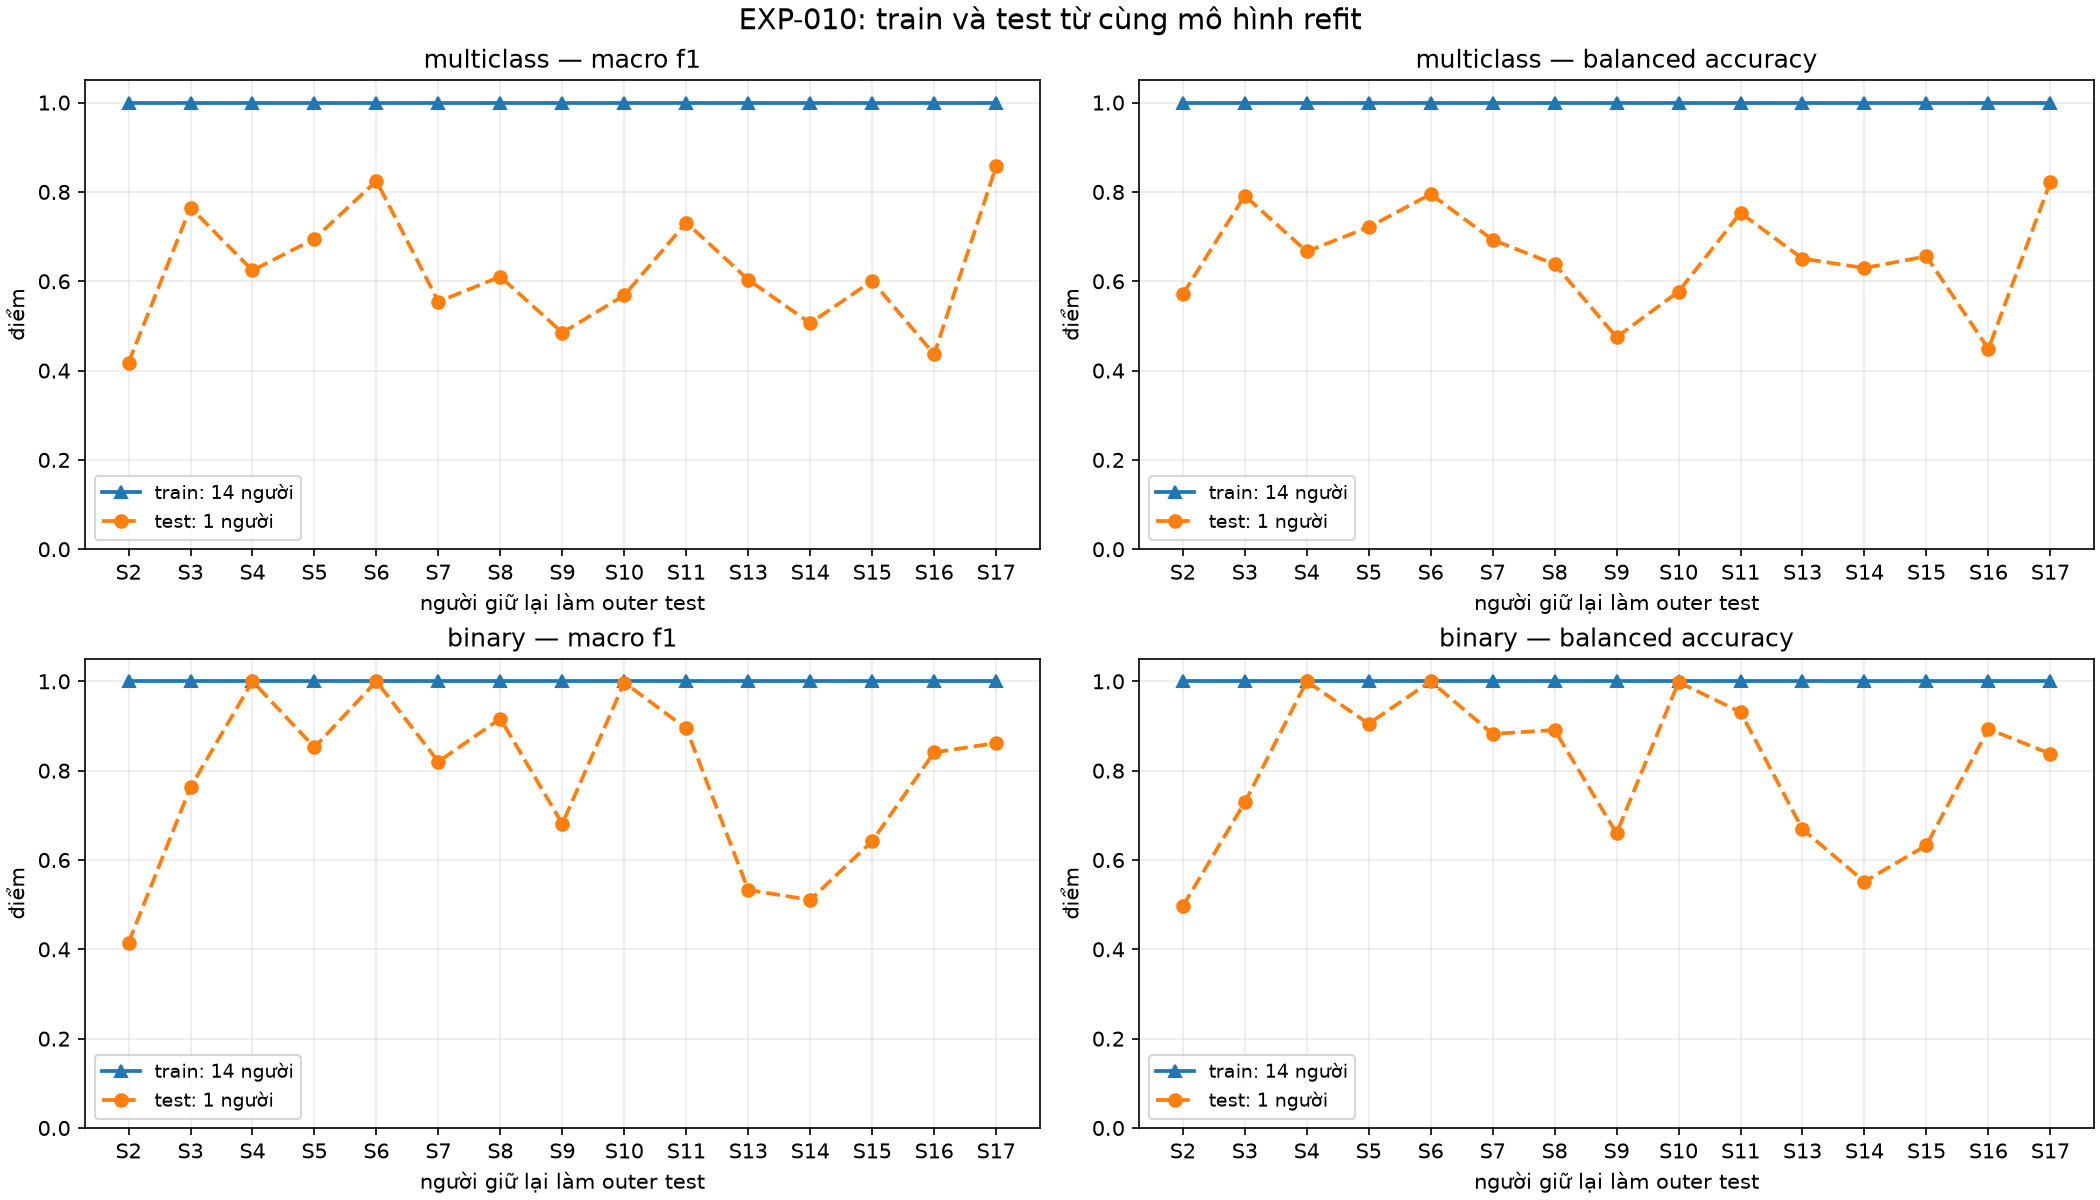

In [2]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image

diagnostic_candidates = [q for p in [Path.cwd(), *Path.cwd().parents]
                         for q in (p, p / "wesad-stress-detection")]
diagnostic_root = next(p for p in diagnostic_candidates
                       if (p / "src/wesad/evaluation.py").is_file())
diagnostic_folder = diagnostic_root / "experiments/02_tuning/EXP-010/results/train_test"
diagnostic_metrics = pd.read_csv(diagnostic_folder / "metrics.csv")
display(diagnostic_metrics[["task", "subject_id", "train_macro_f1",
                            "test_macro_f1", "macro_f1_gap"]].round(4))
display(Image(filename=str(diagnostic_folder / "train_vs_test.png")))
print((diagnostic_folder / "analysis.md").read_text(encoding="utf-8"))
print(json.loads((diagnostic_folder / "verification.json").read_text(encoding="utf-8")))


## chạy thêm ngày 22/11/2026 — seed 43 và 44

như. EXP chung: EXP-010. Chạy mới seed 43/44, mỗi seed đủ 30 fold. Câu hỏi: kết quả thay đổi bao nhiêu khi đổi seed? Giữ dữ liệu và quy trình của EXP này. Seed 42 vẫn là mốc so sánh.

In [1]:
from pathlib import Path
import pandas as pd, json
root=next(p for p in [Path.cwd(),Path.cwd()/'wesad-stress-detection',*Path.cwd().parents] if (p/'src/wesad').is_dir())
folder=root/'experiments/02_tuning/EXP-010/seed_runs/20261122'
print('ngày chạy: 22/11/2026')
print(pd.read_csv(folder/'summary.csv').to_string(index=False))

ngày chạy: 22/11/2026
experiment       task  seed  subjects  macro_f1_mean  macro_f1_sd  ba_mean    ba_sd  train_f1  train_ba  epochs_mean  warnings  max_iter_folds
   EXP-010     binary    42        15       0.781909     0.186880 0.805156 0.168197       1.0       1.0    22.400000         0               0
   EXP-010     binary    43        15       0.858753     0.122177 0.865222 0.124712       1.0       1.0    28.466667         0               0
   EXP-010     binary    44        15       0.833201     0.163883 0.846286 0.151114       1.0       1.0    38.866667         0               0
   EXP-010 multiclass    42        15       0.618670     0.133812 0.659146 0.110440       1.0       1.0    46.600000         0               0
   EXP-010 multiclass    43        15       0.662665     0.115189 0.697181 0.108068       1.0       1.0    34.266667         0               0
   EXP-010 multiclass    44        15       0.610355     0.124864 0.651717 0.102347       1.0       1.0    42.866667    

Thanh sai số là SD giữa 15 người. Seed 42 của EXP010/015 đọc từ lượt chính cũ; điểm train của mốc này lấy từ refit đã kiểm tra khớp dự đoán test. Các lượt mới đo train và test bằng cùng mô hình đang fit. Train chấm trên cửa sổ gốc, trước nhân bản ROS.

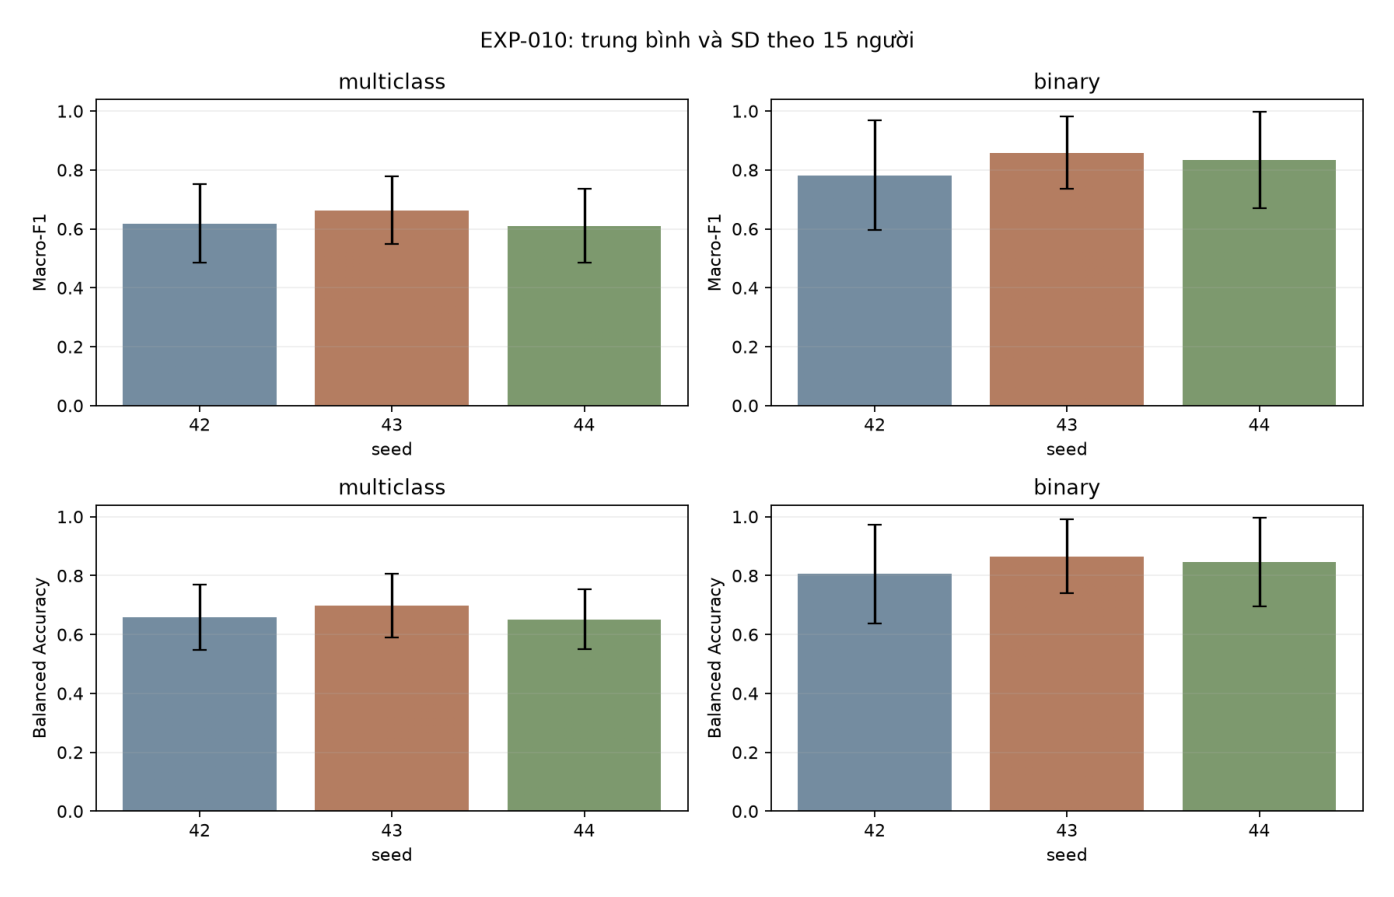

In [2]:
import matplotlib.pyplot as plt
fig=plt.figure(figsize=(11,7))
plt.imshow(plt.imread(folder/'figures/scores.png'))
plt.axis('off')
fig.tight_layout()

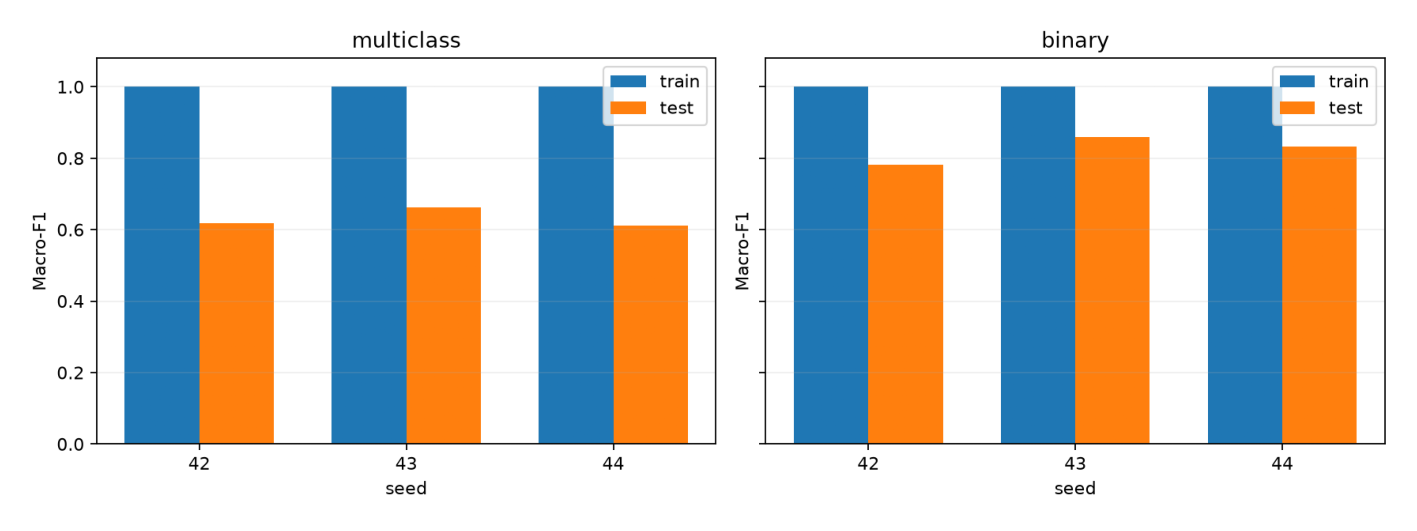

In [3]:
import matplotlib.pyplot as plt
fig=plt.figure(figsize=(11,7))
plt.imshow(plt.imread(folder/'figures/train_test.png'))
plt.axis('off')
fig.tight_layout()

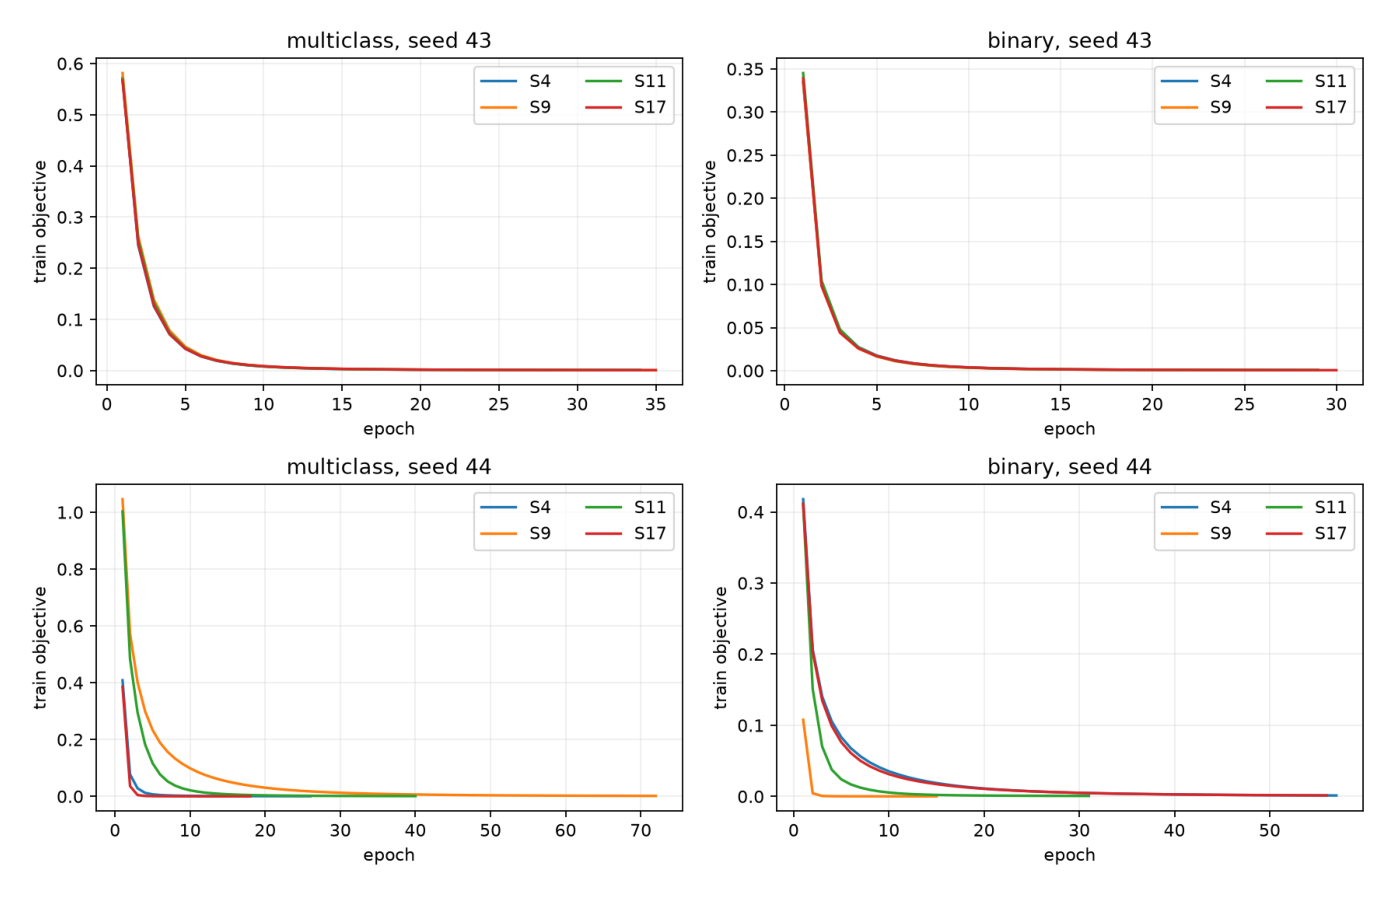

In [4]:
import matplotlib.pyplot as plt
fig=plt.figure(figsize=(11,7))
plt.imshow(plt.imread(folder/'figures/loss.png'))
plt.axis('off')
fig.tight_layout()

Loss là train objective, không phải loss test. Các fold có thể chọn alpha khác nhau; không dùng độ lớn loss để xếp hạng mô hình.

In [5]:
events=[]
for seed in [43,44]:
    events.extend(json.loads(line) for line in (folder/f'seed_{seed}_journal.jsonl').read_text(encoding='utf8').splitlines())
print(pd.DataFrame(events).to_string(index=False))

      date member experiment  seed  status                         note
22/11/2026    như    EXP-010    43 bắt đầu chạy đủ 15 người, 2 bài toán
22/11/2026    như    EXP-010    43    xong     đủ 30 fold, kiểm tra đạt
22/11/2026    như    EXP-010    44 bắt đầu chạy đủ 15 người, 2 bài toán
22/11/2026    như    EXP-010    44    xong     đủ 30 fold, kiểm tra đạt


### ghi chú

Giữ cả lượt tăng và giảm điểm. Không chọn seed tốt nhất. Các lượt dùng cùng 15 người, không phải dữ liệu test mới.